In [1]:
import io
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from pathlib import Path

uploaded = files.upload()

df = pd.read_csv(io.BytesIO(uploaded["clustering_preprocessed.csv"]))

# Use the two features specified in our clustering role.
features = ["tenure", "MonthlyCharges"]
X = df[features].copy()

assert X.notna().all().all(), "Missing values found."
assert np.isfinite(X.to_numpy()).all(), "Non-finite values found."

print("Customers and selected features:", X.shape)
display(X.head())
display(X.describe())

# These features are already standardised. Do not scale again.

Saving clustering_scaler (1).pkl to clustering_scaler (1).pkl
Saving clustering_preprocessed.csv to clustering_preprocessed.csv
Customers and selected features: (7043, 2)


,tenure,MonthlyCharges
0,-1.277445,-1.321350
1,0.351370,-1.321350
2,0.799294,-1.520755
3,-1.277445,0.373593
4,1.410099,-0.457261


,tenure,MonthlyCharges
count,7.043000e+03,7.043000e+03
mean,-1.967284e-17,-1.281257e-16
std,1.000071e+00,1.000071e+00
min,-1.318165e+00,-1.553989e+00
25%,-9.516817e-01,-9.557738e-01
50%,-1.372744e-01,1.741880e-01
75%,9.214551e-01,8.388714e-01
max,1.613701e+00,1.802662e+00


,k,inertia,silhouette
0,1,14086.000000,NaN
1,2,7841.425944,0.410567
2,3,4622.446769,0.449878
3,4,2846.346394,0.473153
4,5,2338.566162,0.424054
5,6,1929.097200,0.416238
6,7,1555.954882,0.431558
7,8,1344.622218,0.427933
8,9,1149.204621,0.438971
9,10,1008.092499,0.427897


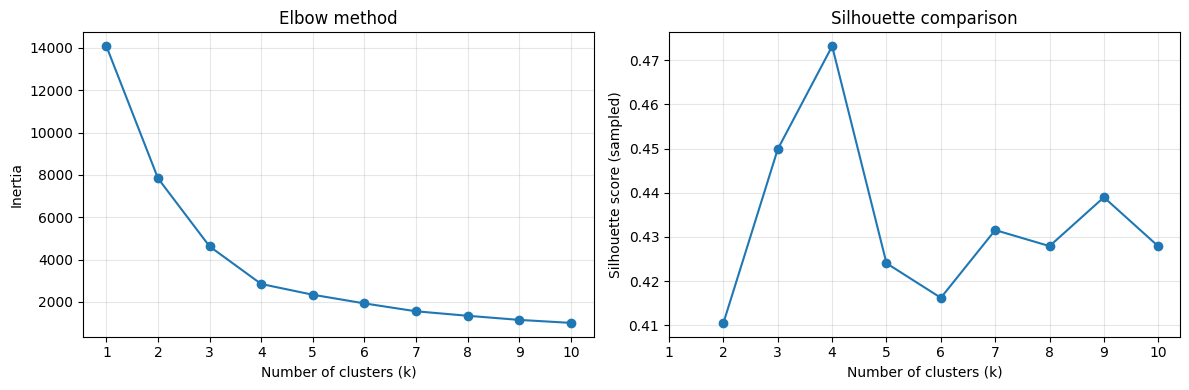

In [2]:
output = Path("Clustering_Analysis")
for folder in ["Optimal_Clusters", "Model", "Visualisations"]:
    (output / folder).mkdir(parents=True, exist_ok=True)

results = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X)

    score = (
        silhouette_score(
            X, labels,
            sample_size=min(3000, len(X)),
            random_state=42
        )
        if k > 1 else np.nan
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": score
    })

metrics = pd.DataFrame(results)
metrics.to_csv(
    output / "Optimal_Clusters/cluster_comparison.csv",
    index=False
)
display(metrics)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics["k"], metrics["inertia"], marker="o")
axes[0].set(
    title="Elbow method",
    xlabel="Number of clusters (k)",
    ylabel="Inertia"
)

axes[1].plot(
    metrics["k"], metrics["silhouette"], marker="o"
)
axes[1].set(
    title="Silhouette comparison",
    xlabel="Number of clusters (k)",
    ylabel="Silhouette score (sampled)"
)

for ax in axes:
    ax.set_xticks(range(1, 11))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    output / "Optimal_Clusters/cluster_selection.png",
    dpi=200
)
plt.show()

In [3]:
from google.colab import files

files.download(
    "Clustering_Analysis/Optimal_Clusters/cluster_selection.png"
)
files.download(
    "Clustering_Analysis/Optimal_Clusters/cluster_comparison.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Customers,Mean_tenure_scaled,Mean_monthly_charges_scaled
Cluster,,,
0,2202,-0.715052,0.547446
1,1733,-0.891506,-1.072563
2,1948,1.074512,0.941099
3,1160,0.884807,-1.017228


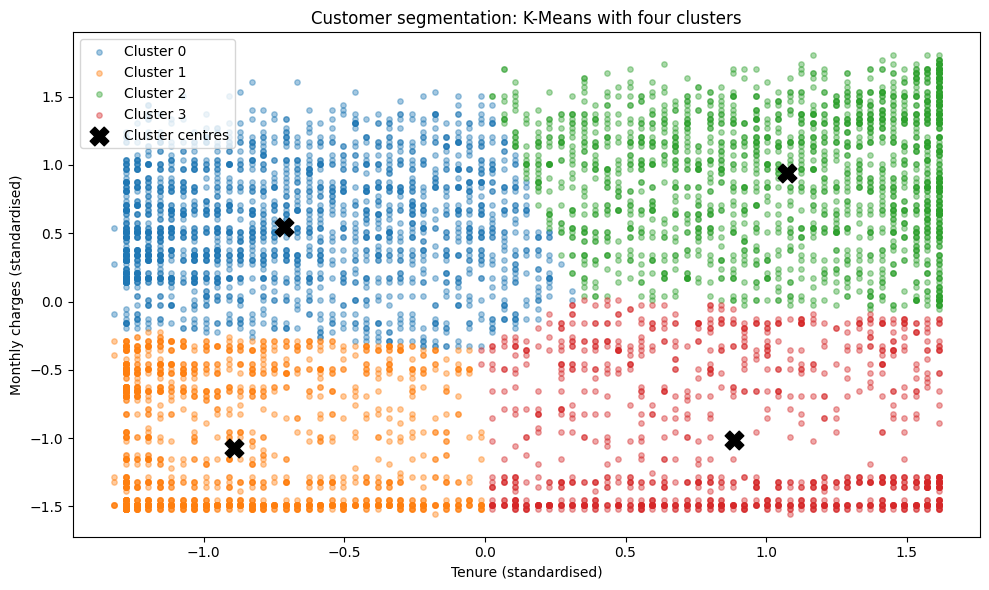

Model and customer cluster assignments saved.


In [4]:
# Train the final model using four clusters.
final_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

cluster_labels = final_model.fit_predict(X)

# Save the trained model and its expected feature order.
joblib.dump(
    {
        "model": final_model,
        "features": features,
        "input": "Already standardised using clustering_scaler.pkl"
    },
    output / "Model/kmeans_model.joblib"
)

# Save cluster assignments alongside the prepared dataset.
clustered_data = df.copy()
clustered_data["Cluster"] = cluster_labels

clustered_data.to_csv(
    output / "Model/customers_with_clusters.csv",
    index=False
)

# Summarise clusters in standardised units.
summary = X.copy()
summary["Cluster"] = cluster_labels

cluster_summary = summary.groupby("Cluster").agg(
    Customers=("tenure", "size"),
    Mean_tenure_scaled=("tenure", "mean"),
    Mean_monthly_charges_scaled=("MonthlyCharges", "mean")
)

display(cluster_summary)

# Visualise the customer groups and their centres.
plt.figure(figsize=(10, 6))

for cluster in range(4):
    mask = cluster_labels == cluster
    plt.scatter(
        X.loc[mask, "tenure"],
        X.loc[mask, "MonthlyCharges"],
        s=15,
        alpha=0.4,
        label=f"Cluster {cluster}"
    )

centres = final_model.cluster_centers_

plt.scatter(
    centres[:, 0],
    centres[:, 1],
    color="black",
    marker="X",
    s=180,
    label="Cluster centres"
)

plt.xlabel("Tenure (standardised)")
plt.ylabel("Monthly charges (standardised)")
plt.title("Customer segmentation: K-Means with four clusters")
plt.legend()
plt.tight_layout()

plt.savefig(
    output / "Visualisations/customer_clusters_scaled.png",
    dpi=200
)
plt.show()

print("Model and customer cluster assignments saved.")

In [5]:
# Find the uploaded clustering scaler, including names with "(1)".
scaler_name = next(
    name for name in uploaded
    if name.lower().endswith(".pkl")
    and "clustering_scaler" in name.lower()
)

scaler = joblib.load(io.BytesIO(uploaded[scaler_name]))

# Confirm that the scaler matches our two selected features.
assert scaler.n_features_in_ == 2, "Scaler feature count differs."

if hasattr(scaler, "feature_names_in_"):
    assert list(scaler.feature_names_in_) == features, (
        "Scaler feature order differs. Check before continuing."
    )

# Convert standardised values back to original units.
original_values = scaler.inverse_transform(X)

interpreted = pd.DataFrame(
    original_values,
    columns=["Tenure_months", "Monthly_charges"],
    index=X.index
)

interpreted["Cluster"] = cluster_labels

segment_names = {
    0: "Shorter tenure, higher charges",
    1: "Shorter tenure, lower charges",
    2: "Longer tenure, higher charges",
    3: "Longer tenure, lower charges"
}

interpreted["Segment"] = interpreted["Cluster"].map(segment_names)

summary_original = interpreted.groupby(
    ["Cluster", "Segment"]
).agg(
    Customers=("Tenure_months", "size"),
    Average_tenure_months=("Tenure_months", "mean"),
    Average_monthly_charges=("Monthly_charges", "mean")
).reset_index()

summary_original["Percentage"] = (
    summary_original["Customers"] / len(interpreted) * 100
)

summary_original.to_csv(
    output / "Visualisations/cluster_summary.csv",
    index=False
)

display(summary_original.round(2))

,Cluster,Segment,Customers,Average_tenure_months,Average_monthly_charges,Percentage
0,0,"Shorter tenure, higher charges",2202,14.81,81.23,31.27
1,1,"Shorter tenure, lower charges",1733,10.48,32.49,24.61
2,2,"Longer tenure, higher charges",1948,58.76,93.08,27.66
3,3,"Longer tenure, lower charges",1160,54.10,34.15,16.47


In [6]:
files.download(
    str(output / "Visualisations/cluster_summary.csv")
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

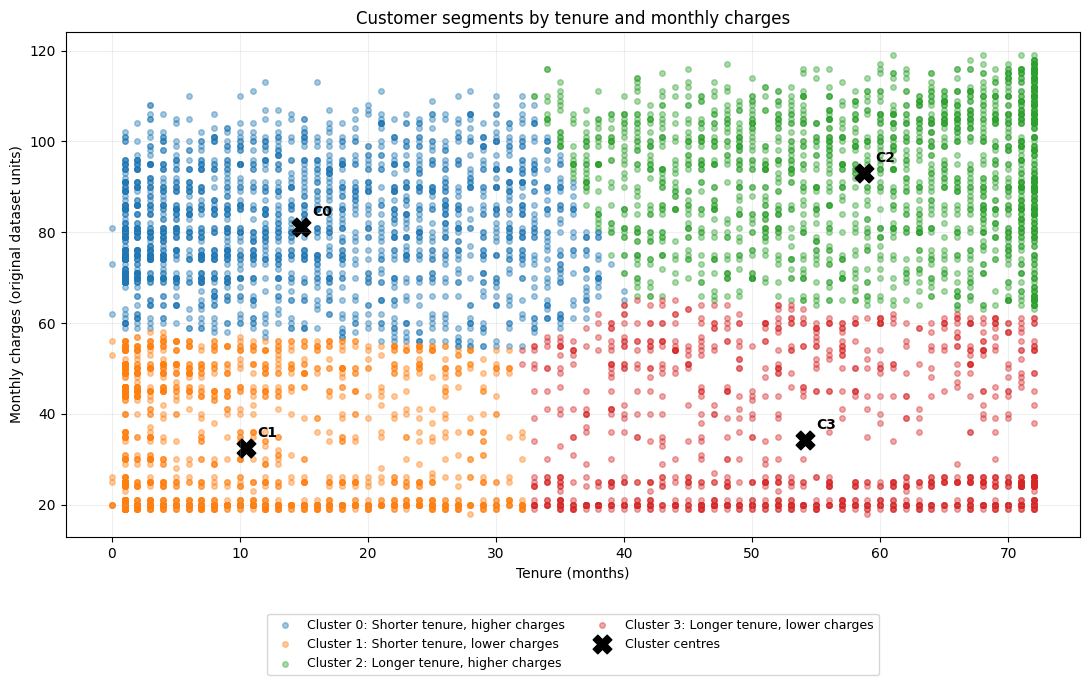

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
fig, ax = plt.subplots(figsize=(11, 7))
colours = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

for cluster in range(4):
    group = interpreted[interpreted["Cluster"] == cluster]

    ax.scatter(
        group["Tenure_months"],
        group["Monthly_charges"],
        color=colours[cluster],
        s=16,
        alpha=0.4,
        label=f"Cluster {cluster}: {segment_names[cluster]}"
    )

# Convert the model's centres back to original units.
centres_original = scaler.inverse_transform(
    final_model.cluster_centers_
)

ax.scatter(
    centres_original[:, 0],
    centres_original[:, 1],
    color="black",
    marker="X",
    s=180,
    label="Cluster centres"
)

for cluster, (tenure, charges) in enumerate(centres_original):
    ax.annotate(
        f"C{cluster}",
        (tenure, charges),
        xytext=(8, 8),
        textcoords="offset points",
        fontweight="bold"
    )

ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Monthly charges (original dataset units)")
ax.set_title("Customer segments by tenure and monthly charges")
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    fontsize=9
)
ax.grid(alpha=0.2)

fig.tight_layout()

graph_path = output / "Visualisations/customer_segments_labelled.png"
fig.savefig(graph_path, dpi=200, bbox_inches="tight")
plt.show()

files.download(str(graph_path))

In [8]:
files.download(str(output / "Model/kmeans_model.joblib"))
files.download(str(output / "Model/customers_with_clusters.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>